In [ ]:
# ==================== CÂU 1 ====================
print("Họ tên: Phan Công Trí - MSSV: 6451071080")

import os
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn import metrics
import seaborn as sns
import plotly as py
import plotly.graph_objs as go
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# 1. Nhập dữ liệu, thống kê các thông tin cơ bản, xử lý dữ liệu bị thiếu
file_path = 'Mall_Customers.csv'
if not os.path.exists(file_path):
    # Tự động tải file chuẩn nếu chưa upload lên Colab
    url = 'https://raw.githubusercontent.com/SteffiPeTaffy/machineLearningAZ/master/Machine%20Learning%20A-Z%20Template%20Folder/Part%204%20-%20Clustering/Section%2025%20-%20Hierarchical%20Clustering/Mall_Customers.csv'
    data = pd.read_csv(url)
    data.to_csv(file_path, index=False)
else:
    data = pd.read_csv(file_path)

# Đổi tên cột nếu file csv có tên 'Genre' thành 'Gender'
if 'Genre' in data.columns:
    data.rename(columns={'Genre': 'Gender'}, inplace=True)

print("5 dòng đầu tiên của dữ liệu:")
display(data.head())

print("\nThông tin bộ dữ liệu:")
print(data.info())

print("\nThống kê mô tả:")
display(data.describe())

print("\nKiểm tra dữ liệu bị thiếu (Null/NaN):")
print(data.isnull().sum())
data.dropna(inplace=True)

Họ tên: Phan Công Trí - MSSV: 6451071080
5 dòng đầu tiên của dữ liệu:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Thông tin bộ dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None

Thống kê mô tả:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Kiểm tra dữ liệu bị thiếu (Null/NaN):
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


Họ tên: Phan Công Trí - MSSV: 6451071080


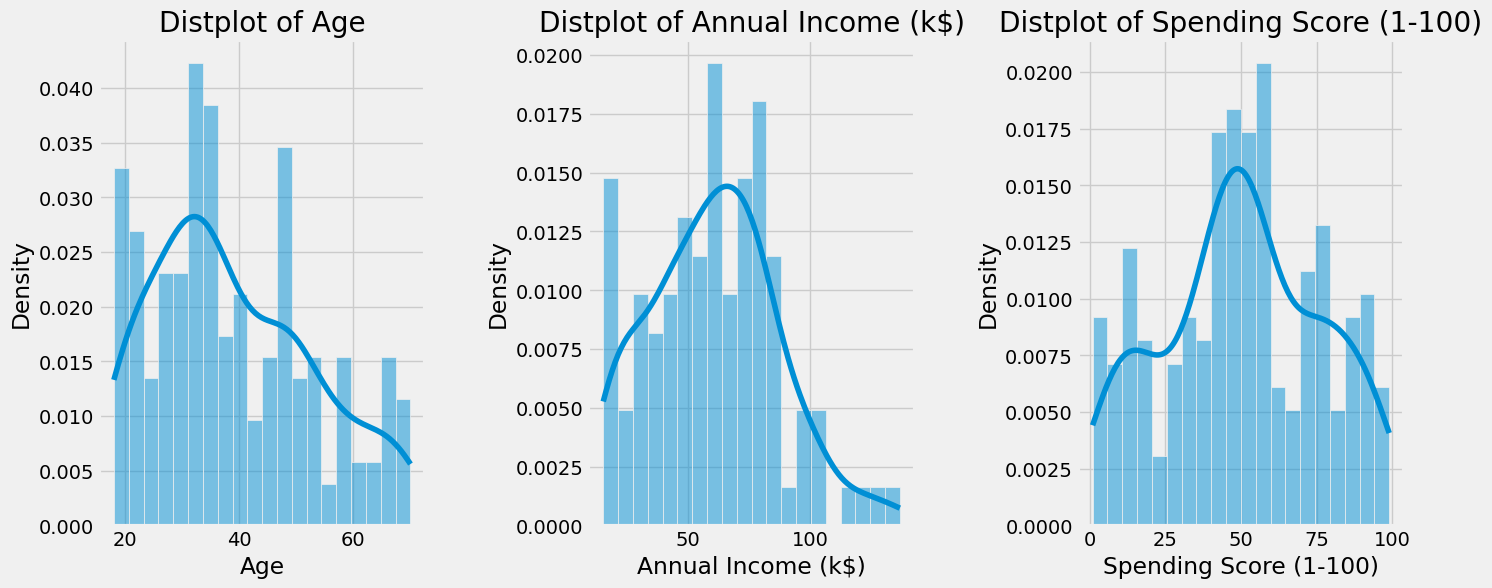

In [ ]:
# ==================== CÂU 2 ====================
print("Họ tên: Phan Công Trí - MSSV: 6451071080")

# 2. Sử dụng biểu đồ tần suất (Histogram) biểu diễn phân phối của Tuổi, Thu nhập, Số điểm mua sắm
plt.style.use('fivethirtyeight')
plt.figure(1, figsize=(15, 6))
n = 0
for x in ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']:
    n += 1
    plt.subplot(1, 3, n)
    plt.subplots_adjust(hspace=0.5, wspace=0.5)
    sns.histplot(data[x], bins=20, kde=True, stat="density")
    plt.title('Distplot of {}'.format(x))
plt.show()

Họ tên: Phan Công Trí - MSSV: 6451071080
Gender
Female    112
Male       88
Name: count, dtype: int64


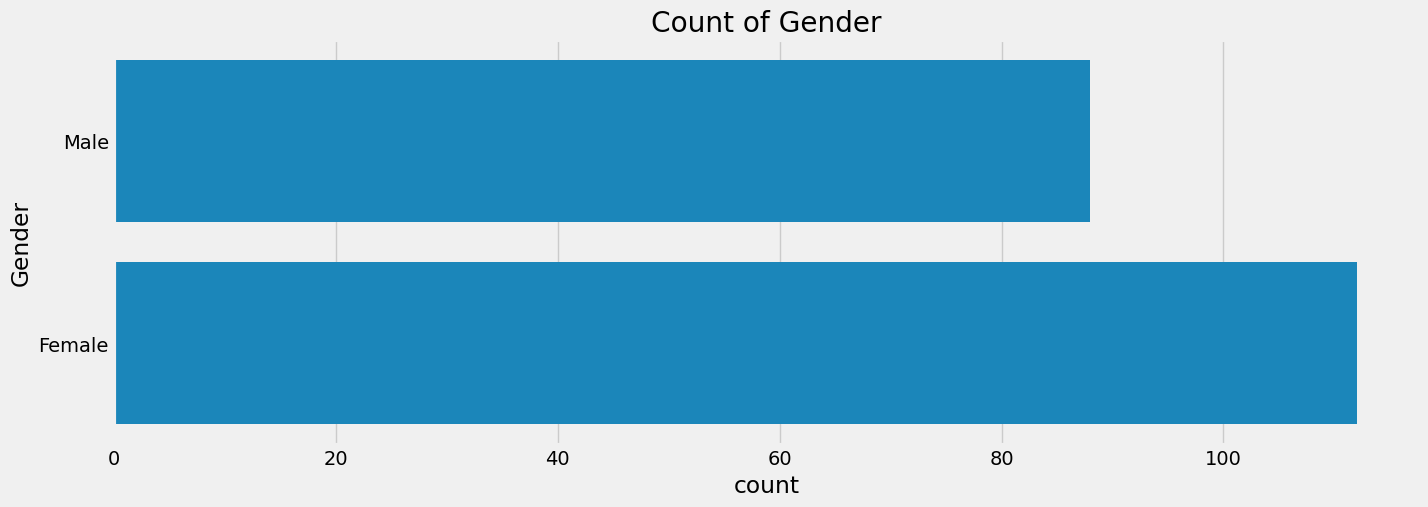

In [ ]:
# ==================== CÂU 3 ====================
print("Họ tên: Phan Công Trí - MSSV: 6451071080")

# 3. Thống kê số mẫu dữ liệu theo thuộc tính Giới tính
print(data['Gender'].value_counts())

plt.figure(1, figsize=(15, 5))
sns.countplot(y='Gender', data=data)
plt.title('Count of Gender')
plt.show()

Họ tên: Phan Công Trí - MSSV: 6451071080


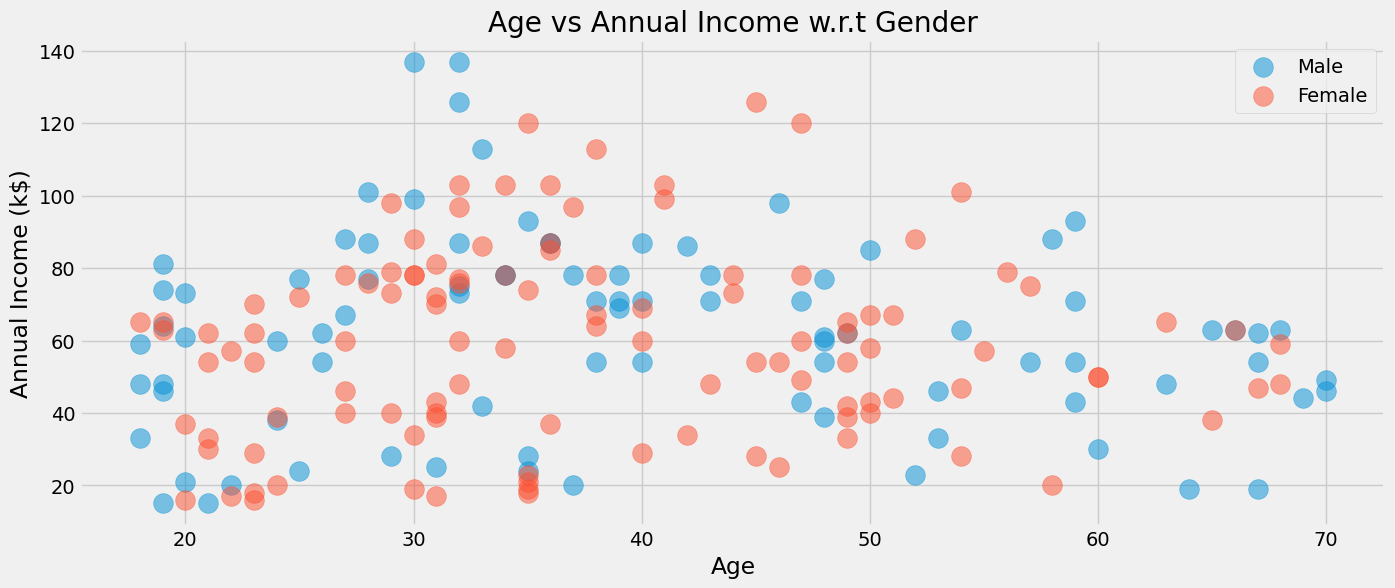

In [ ]:
# ==================== CÂU 4 ====================
print("Họ tên: Phan Công Trí - MSSV: 6451071080")

# 4. Biểu đồ phân tán (Scatter plot) khảo sát Tuổi và Thu nhập hằng năm theo Giới tính
plt.figure(1, figsize=(15, 6))
for gender in ['Male', 'Female']:
    plt.scatter(x='Age', y='Annual Income (k$)', data=data[data['Gender'] == gender],
                s=200, alpha=0.5, label=gender)
plt.xlabel('Age'), plt.ylabel('Annual Income (k$)')
plt.title('Age vs Annual Income w.r.t Gender')
plt.legend()
plt.show()

Họ tên: Phan Công Trí - MSSV: 6451071080


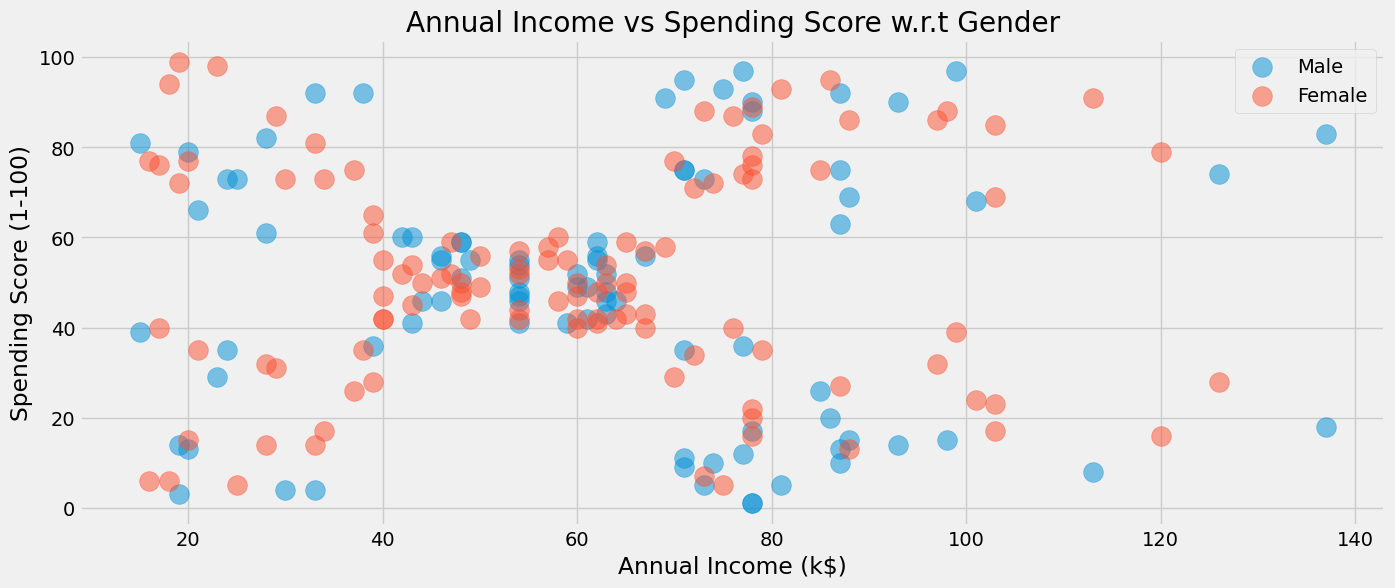

In [ ]:
# ==================== CÂU 5 ====================
print("Họ tên: Phan Công Trí - MSSV: 6451071080")

# 5. Biểu đồ phân tán khảo sát Thu nhập hằng năm và Số điểm mua sắm theo Giới tính
plt.figure(1, figsize=(15, 6))
for gender in ['Male', 'Female']:
    plt.scatter(x='Annual Income (k$)', y='Spending Score (1-100)', data=data[data['Gender'] == gender],
                s=200, alpha=0.5, label=gender)
plt.xlabel('Annual Income (k$)'), plt.ylabel('Spending Score (1-100)')
plt.title('Annual Income vs Spending Score w.r.t Gender')
plt.legend()
plt.show()

Họ tên: Phan Công Trí - MSSV: 6451071080


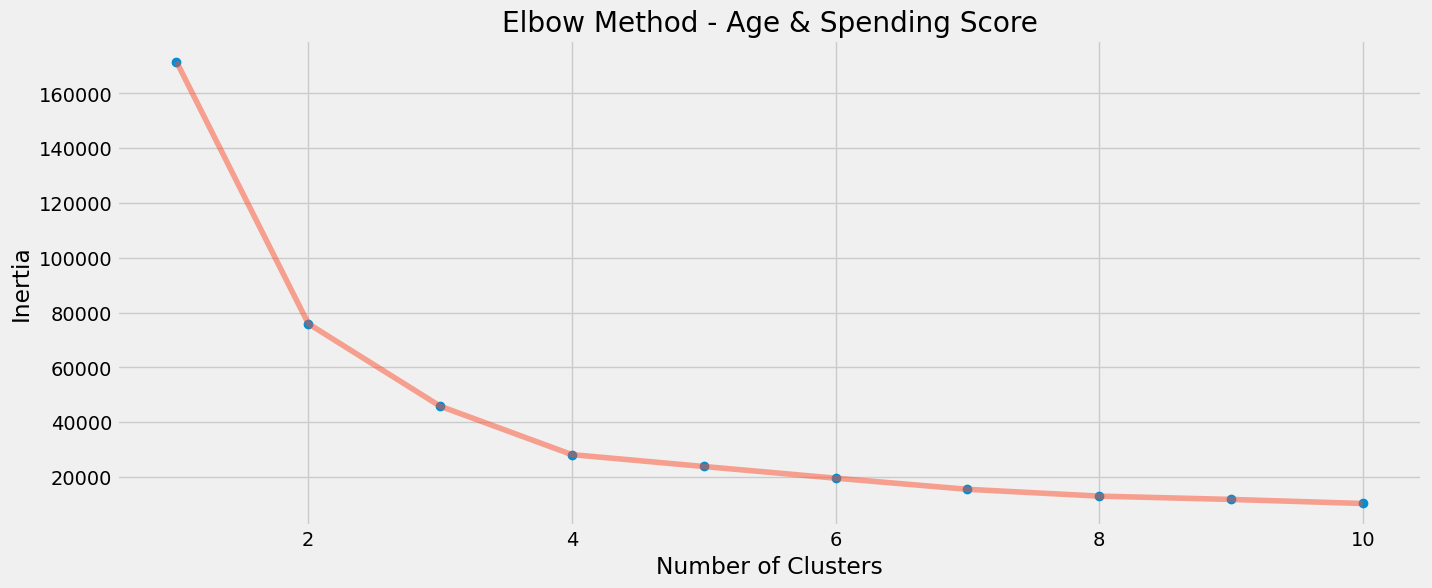

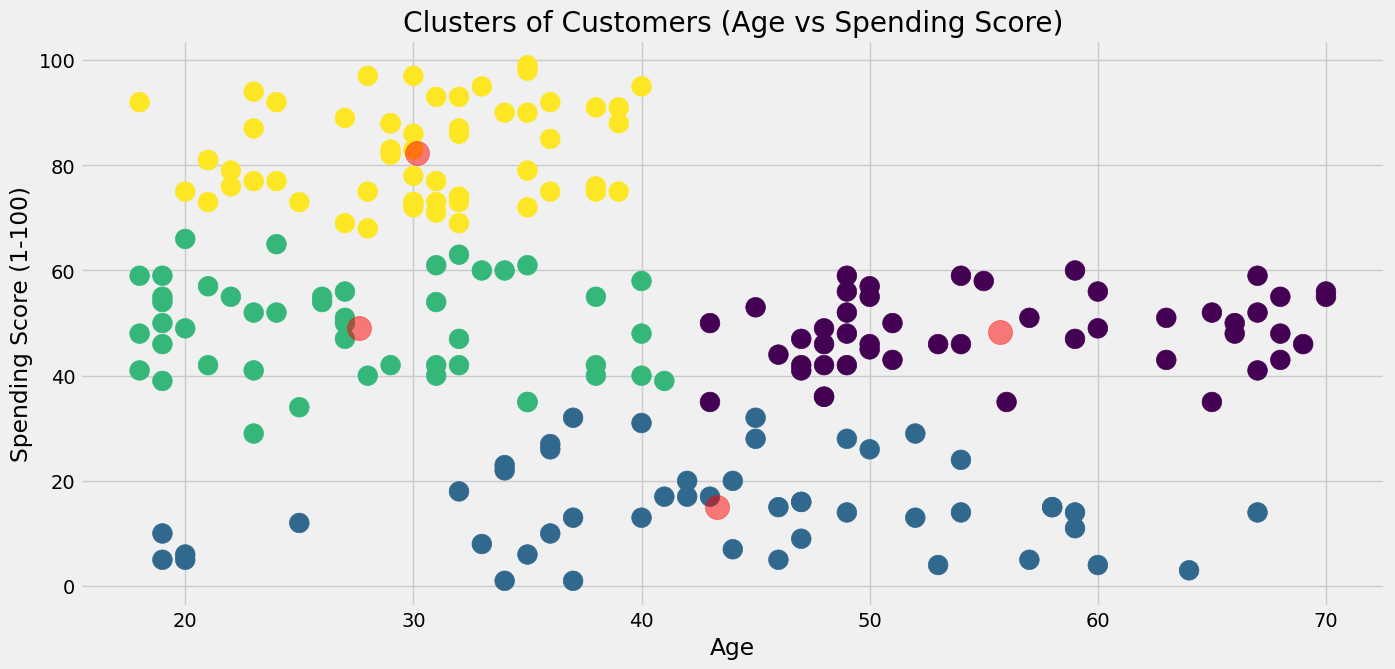

Silhouette Coefficient (Age & Spending Score, k=4): 0.49973941540141753


In [ ]:
# ==================== CÂU 6, 7, 8 ====================
print("Họ tên: Phan Công Trí - MSSV: 6451071080")

# 6. Gom cụm theo Tuổi và Số điểm mua sắm bằng phương pháp ELBOW & K-Means
X1 = data[['Age', 'Spending Score (1-100)']].iloc[:, :].values
inertia = []
for n in range(1, 11):
    algorithm = KMeans(n_clusters=n, init='random', n_init=10, random_state=42)
    algorithm.fit(X1)
    inertia.append(algorithm.inertia_)

plt.figure(1, figsize=(15, 6))
plt.plot(np.arange(1, 11), inertia, 'o')
plt.plot(np.arange(1, 11), inertia, '-', alpha=0.5)
plt.xlabel('Number of Clusters'), plt.ylabel('Inertia')
plt.title('Elbow Method - Age & Spending Score')
plt.show()

# Gom cụm với k = 4
algorithm1 = KMeans(n_clusters=4, init='random', n_init=10, random_state=42)
algorithm1.fit(X1)
labels1 = algorithm1.labels_
centroids1 = algorithm1.cluster_centers_

# 7. Biểu diễn kết quả gom cụm bằng biểu đồ
plt.figure(1, figsize=(15, 7))
plt.clf()
plt.scatter(x='Age', y='Spending Score (1-100)', data=data, c=labels1, s=200, cmap='viridis')
plt.scatter(x=centroids1[:, 0], y=centroids1[:, 1], s=300, c='red', alpha=0.5)
plt.ylabel('Spending Score (1-100)'), plt.xlabel('Age')
plt.title('Clusters of Customers (Age vs Spending Score)')
plt.show()

# 8. Đánh giá kết quả gom cụm bằng Hệ số Dáng điệu (Silhouette coefficient)
sil_score1 = metrics.silhouette_score(X1, labels1, metric='euclidean')
print("Silhouette Coefficient (Age & Spending Score, k=4):", sil_score1)

Họ tên: Phan Công Trí - MSSV: 6451071080


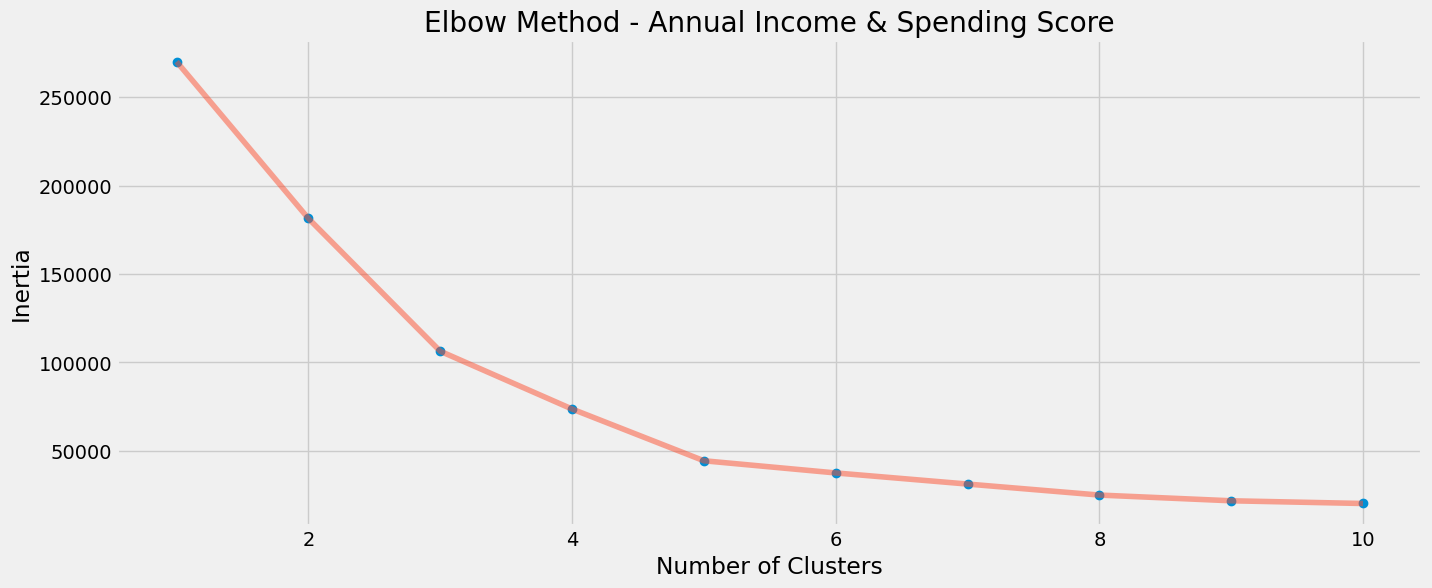

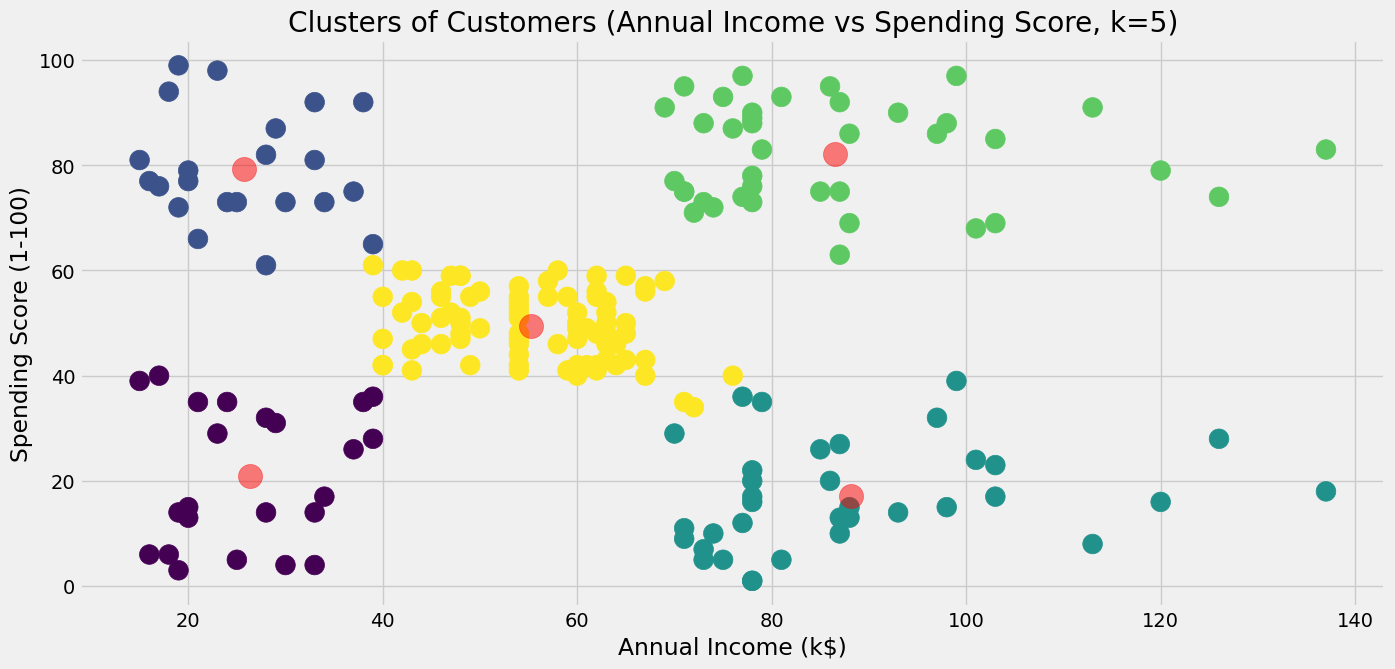

Silhouette Coefficient (Annual Income & Spending Score, k=5): 0.553931997444648


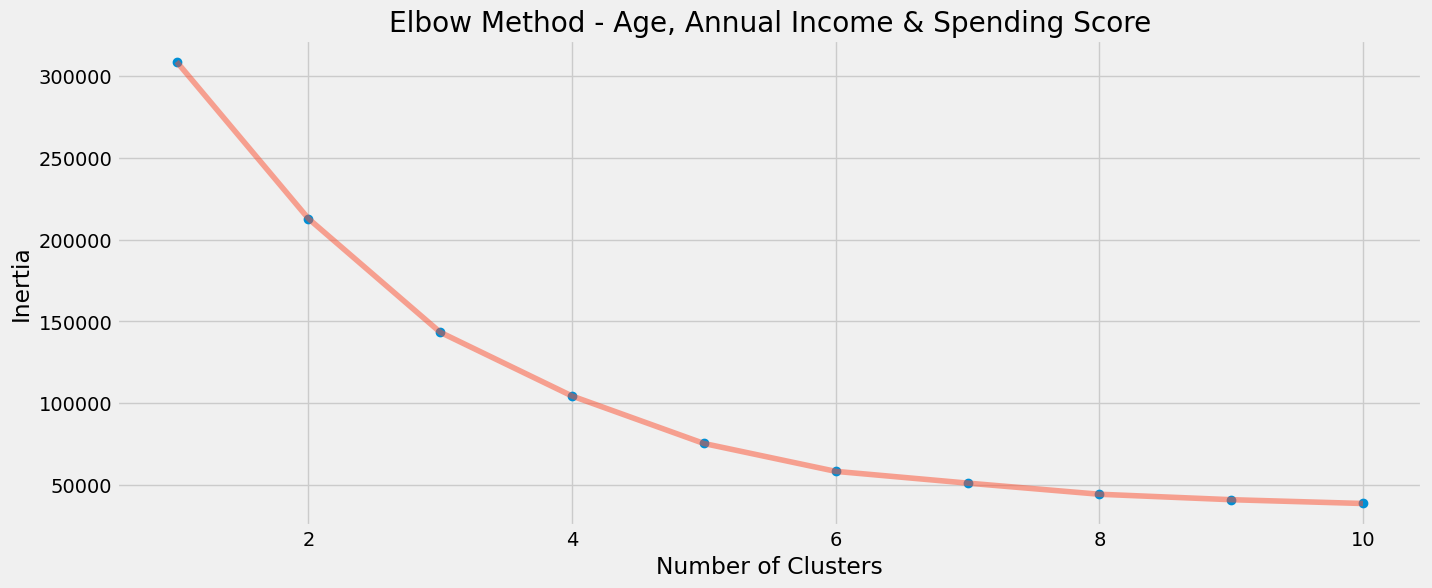

Silhouette Coefficient (3D: Age, Income & Spending Score, k=6): 0.4523566166018854


In [ ]:
# ==================== CÂU 9 ====================
print("Họ tên: Phan Công Trí - MSSV: 6451071080")

# --- 9a. Trường hợp 1: Thu nhập hằng năm và Số điểm mua sắm ---
X2 = data[['Annual Income (k$)', 'Spending Score (1-100)']].iloc[:, :].values
inertia2 = []
for n in range(1, 11):
    algorithm = KMeans(n_clusters=n, init='random', n_init=10, random_state=42)
    algorithm.fit(X2)
    inertia2.append(algorithm.inertia_)

plt.figure(1, figsize=(15, 6))
plt.plot(np.arange(1, 11), inertia2, 'o')
plt.plot(np.arange(1, 11), inertia2, '-', alpha=0.5)
plt.xlabel('Number of Clusters'), plt.ylabel('Inertia')
plt.title('Elbow Method - Annual Income & Spending Score')
plt.show()

# Số cụm tối ưu ở đây là k = 5
algorithm2 = KMeans(n_clusters=5, init='random', n_init=10, random_state=42)
algorithm2.fit(X2)
labels2 = algorithm2.labels_
centroids2 = algorithm2.cluster_centers_

plt.figure(1, figsize=(15, 7))
plt.scatter(x='Annual Income (k$)', y='Spending Score (1-100)', data=data, c=labels2, s=200, cmap='viridis')
plt.scatter(x=centroids2[:, 0], y=centroids2[:, 1], s=300, c='red', alpha=0.5)
plt.ylabel('Spending Score (1-100)'), plt.xlabel('Annual Income (k$)')
plt.title('Clusters of Customers (Annual Income vs Spending Score, k=5)')
plt.show()

sil_score2 = metrics.silhouette_score(X2, labels2, metric='euclidean')
print("Silhouette Coefficient (Annual Income & Spending Score, k=5):", sil_score2)

# --- 9b. Trường hợp 2: Tuổi, Thu nhập hằng năm và Số điểm mua sắm (3D) ---
X3 = data[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].iloc[:, :].values
inertia3 = []
for n in range(1, 11):
    algorithm = KMeans(n_clusters=n, init='random', n_init=10, random_state=42)
    algorithm.fit(X3)
    inertia3.append(algorithm.inertia_)

plt.figure(1, figsize=(15, 6))
plt.plot(np.arange(1, 11), inertia3, 'o')
plt.plot(np.arange(1, 11), inertia3, '-', alpha=0.5)
plt.xlabel('Number of Clusters'), plt.ylabel('Inertia')
plt.title('Elbow Method - Age, Annual Income & Spending Score')
plt.show()

# Số cụm tối ưu cho 3 chiều là k = 6
algorithm3 = KMeans(n_clusters=6, init='random', n_init=10, random_state=42)
algorithm3.fit(X3)
labels3 = algorithm3.labels_
centroids3 = algorithm3.cluster_centers_

sil_score3 = metrics.silhouette_score(X3, labels3, metric='euclidean')
print("Silhouette Coefficient (3D: Age, Income & Spending Score, k=6):", sil_score3)

# Vẽ biểu đồ 3D bằng Plotly
data['label3'] = labels3
trace1 = go.Scatter3d(
    x=data['Age'],
    y=data['Spending Score (1-100)'],
    z=data['Annual Income (k$)'],
    mode='markers',
    marker=dict(
        color=data['label3'],
        size=10,
        line=dict(color=data['label3'], width=12),
        opacity=0.8
    )
)
layout = go.Layout(
    title='Clusters (3D: Age, Spending Score, Annual Income)',
    scene=dict(
        xaxis=dict(title='Age'),
        yaxis=dict(title='Spending Score'),
        zaxis=dict(title='Annual Income')
    ),
    width=900, height=700
)
fig = go.Figure(data=[trace1], layout=layout)
fig.show()